In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import copy
import os
import math
import subprocess

import py3Dmol
import PeptideBuilder
from Bio.PDB import PDBIO

In [2]:
import CBMD

In [3]:
resolution = 100
x = np.linspace(-np.pi, np.pi, resolution)
y = np.linspace(-np.pi, np.pi, resolution)

X, Y = np.meshgrid(x, y)
coords_2d = np.column_stack((X.ravel(), Y.ravel()))

# Functions

In [4]:
def marginalize(mm, dims):
    new_components = []
    for c in mm.components :
        marginals = [c.marginal_distributions[i] for i in dims]
        qs = [c.qs[i] for i in dims]
        rhos = [c.rhos[i] for i in dims]
        new_components.append(CBMD.Wrapped_cauchy_CBMD(marginals, qs, rhos))
    return CBMD.Mixture_model(new_components, mm.weights)

In [5]:
def plot_confidence(ax, dens, color="tab:blue", confs=[0.99, 0.95,0.9,0.75,0.5], writeconfs=True, linestyle="solid"):
    
    def density_contour_levels(Z, levels):
        Z_flat = Z.flatten()
        dx = (x[1] - x[0]) * (y[1] - y[0])

        # sort pdf values in descending order
        Z_sorted = np.sort(Z_flat)[::-1]
    
        # integrate density from top to bottom
        cumsum = np.cumsum(Z_sorted * dx)
        cumsum /= cumsum[-1]
        
        # find pdf values corresponding to confidence intervals
        return [Z_sorted[np.searchsorted(cumsum, level)] for level in levels]

    levels = density_contour_levels(dens, confs)
    mapping = {lvl: label for lvl, label in zip(levels, confs)}
    contours = ax.contour(x, y, dens, levels, colors=color, linewidths=1.0, linestyles=linestyle)
        
    if writeconfs and len(confs) > 1:
        ax.clabel(contours, inline=True, fmt=mapping)


In [6]:
def plot_single_model(ax, mm, dim1, dim2, label1, label2, confs=[0.9,0.75,0.5], writeconfs=True, resolution=50):
    ax.set_xlim(-np.pi, np.pi)
    ax.set_ylim(-np.pi, np.pi)
    
    ax.tick_params(axis="both", which="major")
    ax.set_xticks([-3,-2,-1,0,1,2,3])
    ax.set_yticks([-3,-2,-1,0,1,2,3])
    
    ax.set_xlabel(label1)
    ax.set_ylabel(label2)
    
    ax.set_aspect('equal', adjustable='box')
        
    marg_mm = marginalize(mm, [dim1, dim2])
    dens = marg_mm.pdf(coords_2d).reshape(100, 100)
    
    plot_confidence(ax, dens, "tab:blue", confs=confs, writeconfs=writeconfs, linestyle="solid")
    

In [7]:
def plot_serala_sample(mm, sample):
    fig, axs = plt.subplots(1, 3, figsize=(15,5))
    large_sample = mm.sample(1000)
    
    plot_single_model(axs[0], mm, 0, 1, "phi1", "psi1") 
    axs[0].scatter(large_sample[:,0], large_sample[:,1], c="gray",  s=0.1, alpha=0.7, rasterized=True)
    axs[0].scatter(sample[:,0], sample[:,1], c="red", marker='x', s=5, rasterized=True)

    plot_single_model(axs[1], mm, 3, 1, "phi2", "psi1") 
    axs[1].scatter(large_sample[:,3], large_sample[:,1], c="gray",  s=0.1, alpha=0.7, rasterized=True)
    axs[1].scatter(sample[:,3], sample[:,1], c="red", marker='x', s=5, rasterized=True)

    plot_single_model(axs[2], mm, 3, 4, "phi2", "psi1") 
    axs[2].scatter(large_sample[:,3], large_sample[:,4], c="gray",  s=0.1, alpha=0.7, rasterized=True)
    axs[2].scatter(sample[:,3], sample[:,4], c="red", marker='x', s=5, rasterized=True)

    plt.show()


In [8]:
def plot_serala_data(data):
    fig, axs = plt.subplots(1, 3, figsize=(15,5))
    
    axs[0].scatter(data[:,0], data[:,1], c="blue", marker='x', s=0.1, alpha=0.7, rasterized=True)
    axs[0].set_xlim(-np.pi, np.pi)
    axs[0].set_ylim(-np.pi, np.pi)
    axs[0].tick_params(axis="both", which="major")
    axs[0].set_xticks([-3,-2,-1,0,1,2,3])
    axs[0].set_yticks([-3,-2,-1,0,1,2,3])
    axs[0].set_xlabel("phi1")
    axs[0].set_ylabel("psi1")
    axs[0].set_aspect('equal', adjustable='box')

    axs[1].scatter(data[:,3], data[:,1], c="blue", marker='x', s=0.1, alpha=0.7, rasterized=True)
    axs[1].set_xlim(-np.pi, np.pi)
    axs[1].set_ylim(-np.pi, np.pi)
    axs[1].tick_params(axis="both", which="major")
    axs[1].set_xticks([-3,-2,-1,0,1,2,3])
    axs[1].set_yticks([-3,-2,-1,0,1,2,3])
    axs[0].set_xlabel("phi2")
    axs[0].set_ylabel("psi1")
    axs[1].set_aspect('equal', adjustable='box')

    axs[2].scatter(data[:,3], data[:,4], c="blue", marker='x', s=0.1, alpha=0.7, rasterized=True)
    axs[2].set_xlim(-np.pi, np.pi)
    axs[2].set_ylim(-np.pi, np.pi)
    axs[2].tick_params(axis="both", which="major")
    axs[2].set_xticks([-3,-2,-1,0,1,2,3])
    axs[2].set_yticks([-3,-2,-1,0,1,2,3])
    axs[0].set_xlabel("phi2")
    axs[0].set_ylabel("psi2")
    axs[2].set_aspect('equal', adjustable='box')
    
    plt.show()

In [9]:
def compute_responsibilities(mm, sample):
    resps = np.zeros(shape=(sample.shape[0], len(mm.weights)))

    for i in range(len(mm.weights)):
        weight = mm.weights[i]
        component = mm.components[i]
        resps[:,i] = component.pdf(sample) * weight

    resps_sums = resps.sum(axis=1, keepdims=True)

    resps = resps / resps_sums
        
    return resps

In [10]:
def plot_circular_density(ax, distribution):
    R = 0.0
    
    theta = np.linspace(0, 2*np.pi, 1000)
    theta = np.array([[p] for p in theta])
    
    dens = np.asarray(distribution.pdf(theta))
    r = R + dens
    
    
    ax.set_rlim(-1.0, 2)
    
    ax.plot(theta, np.full_like(theta, R), "k--", linewidth=2)
    
    ax.plot(theta, r, linewidth=2)

   
    
    tick_positions = np.arange(0, 2*np.pi, np.pi/4)
    ax.set_xticks(tick_positions)
    ax.set_xticklabels([ "0", r"$\pi/4$", r"$\pi/2$", r"$3\pi/4$", r"$\pi$", r"$5\pi/4$", r"$3\pi/2$", r"$7\pi/4$"])
    
    


In [11]:
def plot_serine_rotamer(mm, sample):
    fig, ax = plt.subplots(figsize=(5, 5), subplot_kw={"projection": "polar"})

    R = 0.0
    onedmm = marginalize(mm, [2])
    plot_circular_density(ax, onedmm)
    sample = sample[:,2] % (2 * np.pi)

    for angle in sample:
        ax.plot([angle, angle], [R, R + 0.15], color="red", linewidth=1.5, alpha=0.8)



In [12]:
def make_serala_pdbs(sample, dirname):
        
    i = 0
    for torsion_angles in sample:
        phi_ser =  math.degrees(torsion_angles[0])
        psi_ser =  math.degrees(torsion_angles[1])
        omega = 180.0
        
        chi_ser =  math.degrees(torsion_angles[2])
        phi_ala =  math.degrees(torsion_angles[3])
        psi_ala =  math.degrees(torsion_angles[4])
        
        # Build first residue (Gly)
        structure = PeptideBuilder.initialize_res(PeptideBuilder.Geometry.geometry("G"))
        
        # Build Ser with the requested backbone and side-chain torsions
        ser_geo = PeptideBuilder.Geometry.geometry("S")
        ser_geo.phi = phi_ser
        ser_geo.psi_im1 = 130.0  # psi of preceding Gly
        ser_geo.omega = omega
        ser_geo.inputRotamers([chi_ser])
        PeptideBuilder.add_residue(structure, ser_geo)
        
        # Build Ala
        ala_geo = PeptideBuilder.Geometry.geometry("A")
        ala_geo.phi = phi_ala
        ala_geo.psi_im1 = psi_ser
        ala_geo.omega = omega
        PeptideBuilder.add_residue(structure, ala_geo)
        
        # Build final Gly to define psi of Ala
        gly_geo = PeptideBuilder.Geometry.geometry("G")
        gly_geo.phi = -120.0
        gly_geo.psi_im1 = psi_ala
        gly_geo.omega = omega
        PeptideBuilder.add_residue(structure, gly_geo)
        
        # Export complete scaffold (Gly-Ser-Ala-Gly)
        io = PDBIO()
        io.set_structure(structure)
        io.save(dirname + "/observation" + str(i) + ".pdb")
          
        if i > 0:
            
            command = ["python", "sbl-pdb-align.py", "-f", dirname + "/observation0.pdb", dirname + "/observation" + str(i) + ".pdb", "--range", "2", "2"]
            
            with open(os.devnull, "w") as fnull:
                subprocess.call(command, stdout = fnull, stderr = fnull)
            #os.system("python sbl-pdb-align.py -f " + dirname + "/observation0.pdb " + dirname + "/observation" + str(i) + ".pdb --range 2 2> /dev/null")
            
        i+=1
    os.rename(dirname + "/observation0.pdb", dirname + "/observation0-aligned.pdb")
    



In [13]:
def visualize_serala_sample(sample, dirname):
    os.makedirs(dirname, exist_ok=True)
    make_serala_pdbs(sample, dirname)

    view = py3Dmol.view(width=500, height=500)
    
    for i in range(10):
        with open(dirname + "/observation" + str(i) + "-aligned.pdb") as f:
            view.addModel(f.read(), "pdb")
        
        view.setStyle({"model": i}, {})
        
        selection = {"model": i, "resi": [2, 3], "not": {"elem": "H"}}
        view.setStyle(selection, {"stick": {"colorscheme": "Jmol", "radius": 0.15}, "sphere": {"colorscheme": "Jmol", "scale": 0.25}})

    view.zoomTo()
    return view

# Part 1: Clustering

# Part 2 : Toroidal models

## 1 dimension

In [14]:
von_mises = CBMD.Von_mises(np.pi / 2 , 10)

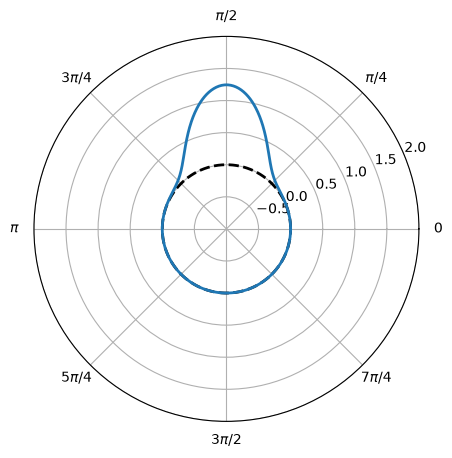

In [15]:
fig, ax = plt.subplots(figsize=(5, 5), subplot_kw={"projection": "polar"})
plot_circular_density(ax, von_mises)

In [16]:
wrapped_cauchy = CBMD.Wrapped_cauchy(np.pi / 2 , 0.75)

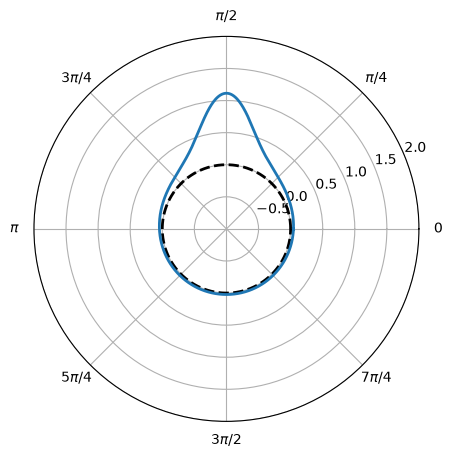

In [17]:
fig, ax = plt.subplots(figsize=(5,5), subplot_kw={"projection": "polar"})
plot_circular_density(ax, wrapped_cauchy)

## 2 dimensions

In [18]:
joint_von_mises = CBMD.Joint_von_mises([0, 0] , [5, 5])

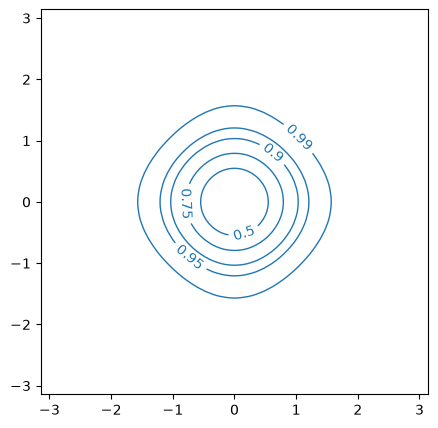

In [19]:
density = joint_von_mises.pdf(coords_2d).reshape(100,100)
fig, ax = plt.subplots(1, 1, figsize=(5,5))
plot_confidence(ax, density)

In [20]:
von_mises_1 = CBMD.Von_mises(0 , 5)
von_mises_2 = CBMD.Von_mises(0 , 5)

vmwc_circula = CBMD.Wrapped_cauchy_CBMD([von_mises_1, von_mises_2], [1.0, 1.0], [0.5, 0.5])

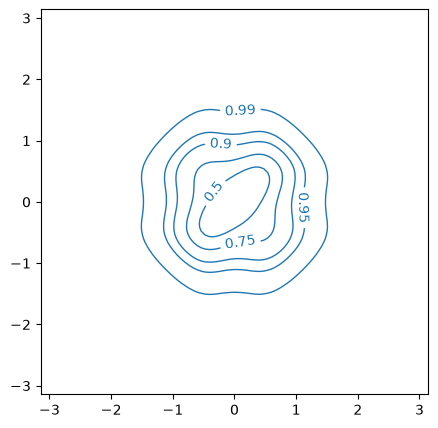

In [21]:
density = vmwc_circula.pdf(coords_2d).reshape(100,100)
fig, ax = plt.subplots(1, 1, figsize=(5,5))
plot_confidence(ax, density)

## >2 dimensions : mixture models

### Load ALA and CYS models

In [22]:
ALA_model = CBMD.Mixture_model.from_file("VMWC_ALA_model.csv", component_type="VMWC")
PRO_model = CBMD.Mixture_model.from_file("VMWC_PRO_model.csv", component_type="VMWC")


### Generate samples

In [23]:
ALA_sample = ALA_model.sample(size=10)
PRO_sample = PRO_model.sample(size=10)

#### Plot ALA

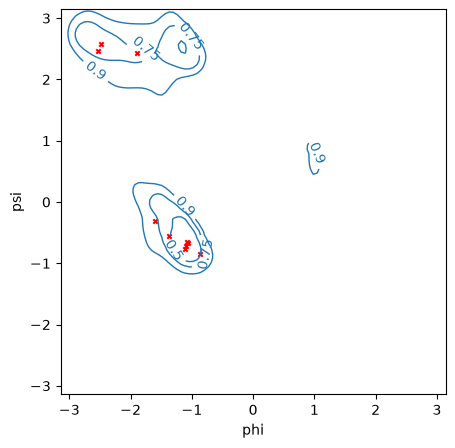

In [24]:
fig, ax = plt.subplots(1, 1, figsize=(5,5))
plot_single_model(ax, ALA_model, 0, 1, "phi", "psi")
ax.scatter(ALA_sample[:,0], ALA_sample[:,1], s=10, marker='x', color='red')

#### Plot PRO

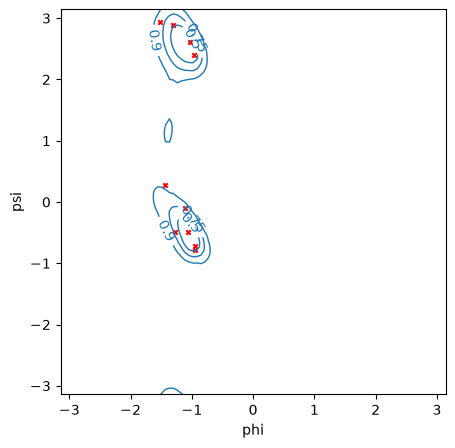

In [25]:
fig, ax = plt.subplots(1, 1, figsize=(5,5))
plot_single_model(ax, PRO_model, 0, 1, "phi", "psi")
ax.scatter(PRO_sample[:,0], PRO_sample[:,1], s=10, marker='x', color='red')

# Part 3 : Conditioning SERALA model on the capping mechanism

## Default SERALA model

### Load SER-ALA pair model

In [26]:
SERALA_model = CBMD.Mixture_model.from_file("VMWC_SER_ALA_model.csv", component_type="VMWC")

### Generate samples

In [27]:
SERALA_sample = SERALA_model.sample(size=10)

### Plot sample

In [ ]:
plot_serala_sample(SERALA_model, SERALA_sample)

In [ ]:
plot_serine_rotamer(SERALA_model, SERALA_sample)

In [ ]:
visualize_serala_sample(SERALA_sample, "default")

## Condition SERALA model using capping data

### Get capping dataset

In [ ]:
#Load SERALA observations
SERALA_df = pd.read_csv("SER_ALA_data")
#Select only observation where SER is not Helix and ALA is Helix (transition)
SERALA_helix_transition_df = SERALA_df[(SERALA_df["dssp1"] != 'H') & (SERALA_df["dssp2"] == 'H')]
SERALA_helix_transition_data = SERALA_helix_transition_df.drop(columns=["dssp1", "dssp2"]).to_numpy()

In [ ]:
plot_serala_data(SERALA_helix_transition_data)

### Condition SERALA model to capping

In [ ]:
# Compute component responsibility for each datapoint
responsibilities = compute_responsibilities(SERALA_model, SERALA_helix_transition_data)
responsibilities_sum = responsibilities.sum(axis=0)

In [ ]:
# Reweight SERALA model using the component responsibilities
SERALA_helix_transition_model = copy.deepcopy(SERALA_model)
SERALA_helix_transition_weights = responsibilities_sum * SERALA_model.weights
SERALA_helix_transition_weights = SERALA_helix_transition_weights / SERALA_helix_transition_weights.sum()
SERALA_helix_transition_model.weights = SERALA_helix_transition_weights

### Generate capping sample

In [ ]:
SERALA_helix_transition_sample = SERALA_helix_transition_model.sample(size=10)

### Plot capping sample

In [ ]:
plot_serala_sample(SERALA_helix_transition_model, SERALA_helix_transition_sample)

In [ ]:
plot_serine_rotamer(SERALA_helix_transition_model, SERALA_helix_transition_sample)

In [ ]:
visualize_serala_sample(SERALA_helix_transition_sample, "helix_transition")